**Change log · Chest pain, Sean's underwriting view**

- **sean v3.1** `Chestpain_Sean_predicates` (2026-11-04) ← **this notebook**
  Zack's answers on the open items: age limits strict (older than 45 and older than 55, completed years at `C`); `no_firm_dx` = none of the diagnoses of the draft up to `R` (was: no CAD, no `explained_dx`, no non-cardiac code); "< 1 year" confirmed as `C` to `R` with any CAD history (words only). The outputs from A4 on are cleared: run again.
- **sean v3** `Chestpain_Sean_predicates` (2026-11-04)
  `R` is the application date of the cohort query v0.3 (`policy.csv`), no longer the last observed event; `C` is still the latest chest pain code on or before `R`. The notebook pulls its own data (A2.1: runs the SQL when the extract folder is missing, then builds parquet). Part B (NMF) removed. New A6: the OMOP concepts behind each predicate and composite. Code sets from `codesets_sean_v2.yaml` (the parameter `CODESETS_FILE` in A1; v2 revises `uw_abnormal_ekg` and `nitrates`, the other tags are as in v1).
- **sean v2** (2026-11-02)
  Added Part B: non-negative matrix factorization (NMF), Sean's groups against the stability-driven fit. Removed in v3 (parked).
- **sean v1** (2026-11-02)
  Sean's draft as predicates and composites, with the prevalence of each. Code sets from `codesets_sean.yaml` only.


# Chest pain · Sean's underwriting view

Sean's draft ("Chest Pain Workflow Draft") lists the **high-risk** and **low-risk features** an underwriter checks for a patient with chest pain, and rules listed under **approve**, **refer** and **decline**.

This notebook turns the draft into **predicates** (each fact as a yes / no per patient) and **composites** (each rule as a combination of predicates), counts how many patients meet each (A1 to A5), lists the OMOP concepts behind them (A6) and tests the time cut-offs (A7). It counts who meets the criteria: no decision, no precedence between rows.

**Clock.** `R` is the index date: the application date of the patient (`policy.csv`, from the cohort query v0.3). Events after `R` are ignored. `C` is the most recent chest pain code on or before `R`; months out is `R - C`; "later coded" means after `C`; age and sex are read at `C`.

**Not in claims.** Test results ("abnormal", "normal", "within normal limits") and the table (TO) rating. Both are listed, not guessed.

*Abbreviations: coronary artery disease (CAD), electrocardiogram (EKG), gastroesophageal reflux disease (GERD), gastrointestinal (GI), diagnosis (Dx), history (Hx).*


**Contents**

- A1 · Settings
- A2 · Data
  - A2.1 · Extract (once)
  - A2.2 · Load
- A3 · One row per patient
- A4 · Predicates
  - A4.1 · Definitions
  - A4.2 · Prevalence
- A5 · Composites
- A6 · OMOP entities behind the rules
- A7 · Sensitivity to the time cut-offs
- A8 · Limits and open questions
- A9 · Export


## A1 · Settings

What to run (smoke or full), the code-set file and Sean's cut-offs.


In [1]:
SMOKE         = False      # True: 5,000 random patients, to see the notebook run in a minute
SMOKE_N       = 5_000
CODESETS_FILE = 'codesets_sean_v2.yaml'   # the code-set file: codesets_sean.yaml (v1) or codesets_sean_v2.yaml (abnormal EKG and nitrates revised, 2026-11-03)
MONTH         = 30.4375    # days in a month
CUT           = {'recent': 6, 'cad': 12, 'old': 24}   # months: Sean's "6 months out", "Hx of CAD and < 1 year", "coded > 2 years ago"
AGE_RULES     = (('M', 45), ('F', 55))                # older than: a man over 45, a woman over 55, at C, in completed years (46+ and 56+); strict, Zack 2026-11-04
NEEDED        = ['chest_pain', 'uw_cad_dx', 'uw_abnormal_ekg', 'uw_cardiac_testing', 'nitrates', 'troponin', 'ekg', 'gerd', 'anxiety',
                 'uw_gi_dx', 'uw_muscle_strain', 'costochondritis', 'uw_noncardiac_cp']   # the 13 code sets of CODESETS_FILE

## A2 · Data

### A2.1 · Extract (once)

Until `extract_complete.txt` is in the extract folder, the cohort query `sql/chest_pain_cohort.sql` (v0.3: `person_id` and the application date) runs in Snowflake (browser sign-in, `SNOWFLAKE_*` variables in the environment) and the tables are streamed to CSV in blocks of 500,000 rows; the application date goes to `policy.csv`. A table that fails on a network error is retried 4 times, 60 seconds apart, first on the same connection and then on a new one (the browser sign-in may open again). A table gets its file name only when it is complete, so if it still fails, run the cell again: it keeps the finished tables, checks that they belong to the same cohort and fetches the rest. The tables are then copied to parquet, once (a failure there is not fatal). To pull again, move the folder away.


In [2]:
import os
import ethos_omop as eo
import csv_to_parquet

OUT_DIR    = "../../inputs/chest_pain_cohort/"    # extract_cohort() output, relative to this notebook's folder
COHORT_SQL = "../../sql/chest_pain_cohort.sql"     # v0.3: person_id and the application date (latest interview start of the person's policies)

# Runs until the extract is complete (the file extract_complete.txt). The cohort query runs in Snowflake (browser sign-in) and each table is streamed
# to CSV in blocks of eo.CHUNK_ROWS rows; the query's second column becomes policy.csv. A table that fails on a network error is retried eo.RETRIES times,
# eo.RETRY_PAUSE seconds apart (first on the same connection, then on a new one: the browser sign-in may open again). A table gets its file name only
# when complete, so if it still fails, run this cell again: resume=True keeps the finished tables and fetches the rest (it refuses a folder of another cohort).
if not os.path.exists(os.path.join(OUT_DIR, eo.EXTRACT_DONE)):
    eo.extract_cohort(COHORT_SQL, out_dir=OUT_DIR, resume=True)
else:
    print(f"{OUT_DIR} already complete -- skipping extract_cohort(). Move the folder away to re-pull from Snowflake.")

# Parquet copies of the tables (about 20x smaller, loaded by column): built once, and again after any re-extract. Only a speed-up: if the build
# fails the notebook prints why and reads the CSVs.
try:
    stale = [t for t in csv_to_parquet.TABLES
             if os.path.exists(os.path.join(OUT_DIR, f"{t}.csv")) and not eo._fresh_parquet(OUT_DIR, t)]
    if stale:
        print("building parquet for:", ", ".join(stale))
        csv_to_parquet.main(OUT_DIR)
    else:
        print("parquet files are up to date")
except Exception as e:
    print(f"parquet build failed ({type(e).__name__}: {e}); the notebook reads the CSVs instead")


../../inputs/chest_pain_cohort/ already complete -- skipping extract_cohort(). Move the folder away to re-pull from Snowflake.
parquet files are up to date


### A2.2 · Load

One pass over the events: Sean's code sets only, everything else is dropped. A concept in two code sets counts in both. Each patient's `R` is the application date. The counts of the code-set table are over all dates; A3 cuts at `R`.


In [3]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt
pd.set_option('display.width', 160); pd.set_option('display.max_columns', 40); pd.set_option('display.max_colwidth', 120)

concept  = eo.load_concept(OUT_DIR)
codesets = eo.build_codesets(concept, codesets=eo._load_codesets(CODESETS_FILE), verbose=True)      # tag -> set of concept_id
missing  = [t for t in NEEDED if t not in codesets]
assert not missing, f"code sets missing from {CODESETS_FILE}: {missing}"
person   = eo.load_person(OUT_DIR)
app      = eo.load_policy_dates(OUT_DIR)       # application date per person: policy.csv, written by the extract of A2.1
assert app is not None, f"{OUT_DIR}policy.csv (person_id, application_date) is missing or empty: the extract of A2.1 writes it from sql/chest_pain_cohort.sql v0.3"

ids = person['person_id'].drop_duplicates()
n_extract = len(ids)
ids = ids[ids.isin(app.index)].to_numpy()
print(f"{n_extract:,} persons in the extract; {len(ids):,} have an application date and form the cohort; {n_extract - len(ids):,} have none and are left out")
if SMOKE:
    ids = np.random.default_rng(0).choice(ids, SMOKE_N, replace=False)
ref = app.reindex(ids).rename('ref_date').to_frame()        # per patient: R, the application date
ref.index.name = 'person_id'

raw = eo.load_events(OUT_DIR, domains=['Condition', 'Drug', 'Procedure', 'Measurement'])
_ids = set().union(*(codesets[t] for t in NEEDED))
ev_any = raw.loc[raw['person_id'].isin(ref.index) & raw['concept_id'].isin(_ids), ['person_id', 'event_date', 'concept_id']].reset_index(drop=True)
print(f"{len(raw):,} events read; {len(ev_any):,} events of Sean's code sets kept for {len(ref):,} patients")
del raw
print(f"application date R: {ref['ref_date'].min().date()} to {ref['ref_date'].max().date()}")

rows = [{'code set': t, 'concepts': len(codesets[t]), 'events, any date': int(ev_any['concept_id'].isin(codesets[t]).sum()),
         'patients, any date': ev_any.loc[ev_any['concept_id'].isin(codesets[t]), 'person_id'].nunique()} for t in NEEDED]
cs_tbl = pd.DataFrame(rows).set_index('code set')
cs_tbl['flag'] = np.where(cs_tbl['patients, any date'] == 0, 'EMPTY', '')
display(cs_tbl)


chest_pain           4 concepts   e.g. ['Chest pain', 'Chest pain on breathing']
uw_cad_dx           22 concepts   e.g. ['Acute ST segment elevation myocardial infarction', 'Acute ST segment elevation myocardial infarction due to left coronary artery occlusion']
uw_abnormal_ekg      1 concepts   e.g. ['Electrocardiogram abnormal']
uw_cardiac_testing    55 concepts   e.g. ['Absolute quantitation of myocardial blood flow (AQMBF), positron emission tomography (PET), rest and pharmacologic stress (List separately in addition to code for primary procedure)', 'CT of heart without contrast with calcium scoring']
nitrates            22 concepts   e.g. ['24 HR isosorbide mononitrate 120 MG Extended Release Oral Tablet', '24 HR isosorbide mononitrate 30 MG Extended Release Oral Tablet']
troponin             2 concepts   e.g. ['Troponin, qualitative', 'Troponin, quantitative']
ekg                  5 concepts   e.g. ['Electrocardiogram, routine ECG with at least 12 leads; interpretation and report

,concepts,"events, any date","patients, any date",flag
code set,,,,
chest_pain,4,487549,150697,
uw_cad_dx,22,48644,10685,
uw_abnormal_ekg,1,42224,17080,
uw_cardiac_testing,55,171712,53600,
nitrates,22,3522,1753,
troponin,2,176450,61364,
ekg,5,561309,123868,
gerd,4,300613,50833,
anxiety,12,604290,55537,


## A3 · One row per patient

`R`, the first and most recent chest pain code (`F`, `C`), `months_out = (R - C) / 30.4375`, and the first and last date of each code set. Events after `R` are dropped first. Population: patients with a chest pain code on or before `R`; the rest are counted and left out.


In [4]:
ev = ev_any.join(ref['ref_date'], on='person_id')                              # events of Sean's code sets, any date
late_cp = ev.loc[ev['concept_id'].isin(codesets['chest_pain']) & (ev['event_date'] > ev['ref_date']), 'person_id'].unique()   # chest pain coded after R
ev = ev[ev['event_date'] <= ev['ref_date']].drop(columns='ref_date')         # what a reader sees at the application date: later events are ignored

span = {}                                                                     # code set -> first and last event date per patient
for tag in NEEDED:
    d = ev.loc[ev['concept_id'].isin(codesets[tag]), ['person_id', 'event_date']]
    span[tag] = d.groupby('person_id')['event_date'].agg(first='min', last='max')

pt = ref.copy()                                                               # one row per patient with an application date
def when(tag, which):
    """first / last date of a code set per patient, NaT when the patient has none."""
    return pd.to_datetime(span[tag][which]).reindex(pt.index)

pt['F'] = when('chest_pain', 'first')
pt['C'] = when('chest_pain', 'last')
n_cohort = len(pt)
pt = pt[pt['C'].notna()].copy()                                               # the population: patients with a chest pain code on or before R
pt['months_out'] = (pt['ref_date'] - pt['C']).dt.days / MONTH
_p = person.drop_duplicates('person_id').set_index('person_id').reindex(pt.index)
pt['sex']   = eo._sex(_p['gender'])
pt['birth'] = _p['birth_date']
pt['age_at_C'] = (pt['C'] - pt['birth']).dt.days / 365.25                    # for reading only; the rule below counts completed years exactly
age_ok = pd.Series(False, index=pt.index)
for _s, _a in AGE_RULES:
    age_ok |= (pt['sex'] == _s) & (pt['C'] >= pt['birth'] + pd.DateOffset(years=_a + 1))      # strictly older than _a: the birthday of _a + 1 has come

N = len(pt)
n_late = len(set(late_cp) - set(pt.index))                                   # chest pain coded, but only after R
print(f"{n_cohort:,} patients with an application date; {N:,} have a chest pain code on or before R and form the population; "
      f"{n_cohort - N:,} do not and are left out of every count below ({n_late:,} of them have chest pain codes only after R)")
print("\nmonths out (R - C):")
print(pt['months_out'].describe(percentiles=[.1, .25, .5, .75, .9]).round(1).to_string())
display(pt[['ref_date', 'F', 'C', 'months_out', 'sex', 'age_at_C']].head(6))

150,697 patients with an application date; 150,664 have a chest pain code on or before R and form the population; 33 do not and are left out of every count below (33 of them have chest pain codes only after R)

months out (R - C):
count    150664.0
mean         35.1
std          23.5
min           0.0
10%           5.6
25%          14.5
50%          32.3
75%          53.7
90%          70.0
max         105.2


,ref_date,F,C,months_out,sex,age_at_C
person_id,,,,,,
5280934,2026-11-03,2025-02-26,2025-02-26,20.205339,M,56.563997
5280954,2026-11-04,2024-10-21,2024-10-21,24.443532,M,37.735797
5281003,2026-11-03,2026-03-10,2026-03-10,7.819302,M,59.931554
5281012,2026-11-03,2024-02-03,2024-02-03,32.985626,M,22.978782
5281039,2026-11-03,2020-07-26,2020-07-26,75.268994,F,40.772074
5281040,2026-11-03,2024-08-06,2025-01-15,21.585216,M,34.151951


## A4 · Predicates

One yes / no per patient. **Time forms:** *up to R*, *at or before C* (history), *after C* (later coded); same-day events count as at or before `C`.

### A4.1 · Definitions

| group | predicate | Sean's words | rule |
|---|---|---|---|
| high risk | `age_sex_high_risk` | Male > 45, Female > 55 | man older than 45 or woman older than 55 at `C`, in completed years (46+ and 56+; strict, Zack 2026-11-04) |
| high risk | `hx_cad` | Previous Dx of CAD | `uw_cad_dx` at or before `C` |
| high risk | `abnormal_ekg` | Abnormal EKG | `uw_abnormal_ekg` up to `R` (the coded finding only) |
| high risk | `extra_cardiac_testing` | Additional cardiac testing | `uw_cardiac_testing` after `C` |
| high risk | `rx_nitrates` | Rx nitrates | `nitrates` up to `R` |
| low risk | `troponin`, `ekg` | Troponin testing, EKG | the test, up to `R` |
| low risk | `gerd`, `anxiety` | GERD, Anxiety | up to `R` |
| later coded | `gi_dx` | GERD, other GI related Dx | `gerd` or `uw_gi_dx` after `C` |
| later coded | `anxiety_later`, `muscle_strain`, `costochondritis` | anxiety, muscle strain, costochondritis | after `C` |
| later coded | `noncardiac_cp` | later noted as intercostal or non-cardiac chest pain | a `uw_noncardiac_cp` code after the first chest pain code `F` (those are chest pain codes themselves, so "after `C`" would never hold) |
| derived | `explained_dx` | anxiety, GI, muscle strain or costochondritis later coded | any of `anxiety_later`, `gi_dx`, `muscle_strain`, `costochondritis` |
| derived | `ekg_no_abnormal_code` | EKG normal | `ekg` and not `abnormal_ekg` (a claims proxy: no result values) |
| derived | `no_further_cardiac_testing` | No further cardiac testing | not `extra_cardiac_testing` |
| derived | `no_firm_dx` | No firm diagnosis | none of the diagnoses of the draft up to `R`: no `uw_cad_dx`, `gerd`, `uw_gi_dx`, `anxiety`, `uw_muscle_strain`, `costochondritis`, `uw_noncardiac_cp` (Zack 2026-11-04) |

### A4.2 · Prevalence

Prevalence of every predicate (table and chart), and the facts that cannot be computed from claims.

,group,n,% of patients
age_sex_high_risk,high risk,54376,36.1
hx_cad,high risk,8187,5.4
abnormal_ekg,high risk,17072,11.3
extra_cardiac_testing,high risk,22818,15.1
rx_nitrates,high risk,1750,1.2
troponin,low risk,61341,40.7
ekg,low risk,123829,82.2
gerd,low risk,50809,33.7
anxiety,low risk,55507,36.8
gi_dx,later coded,34427,22.9


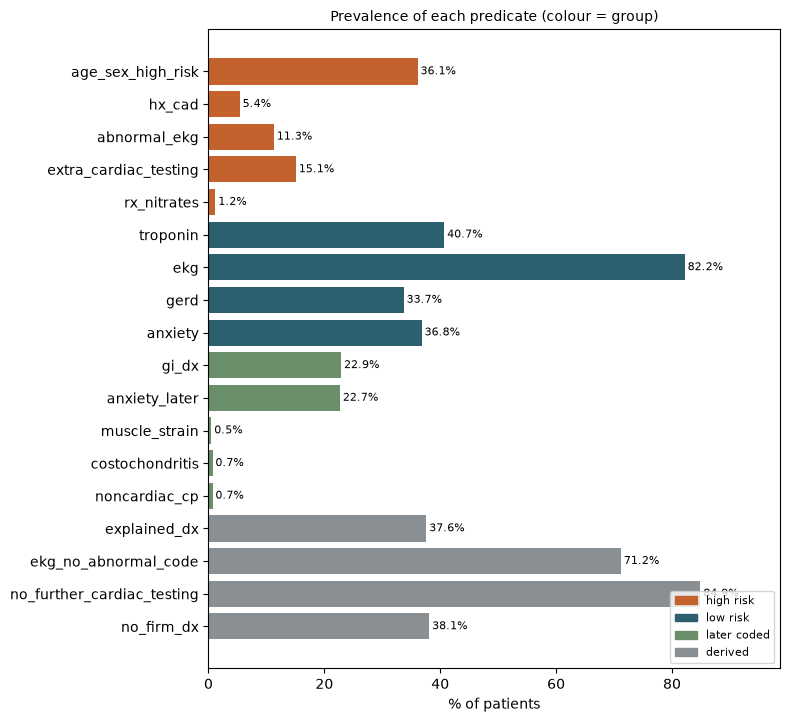

Sean item,why it is not computed
Current TO (table) rating,"underwriting data, not in claims"
Any abnormal testing,needs result values; claims carry codes and dates only (the coded EKG finding is `abnormal_ekg`)
EKG normal,needs the result; `ekg_no_abnormal_code` is the proxy: an EKG and no abnormal-EKG code
All cardiac testing within normal limits,needs result values


In [5]:
upto_R = lambda tag: when(tag, 'first').notna()                    # events after R are already dropped
at_C   = lambda tag: when(tag, 'first') <= pt['C']                 # NaT (no event, or no C) compares False
after_C = lambda tag: when(tag, 'last') > pt['C']

P = pd.DataFrame(index=pt.index)
P['age_sex_high_risk']      = age_ok
P['hx_cad']                 = at_C('uw_cad_dx')
P['abnormal_ekg']           = upto_R('uw_abnormal_ekg')
P['extra_cardiac_testing']  = after_C('uw_cardiac_testing')
P['rx_nitrates']            = upto_R('nitrates')
P['troponin']               = upto_R('troponin')
P['ekg']                    = upto_R('ekg')
P['gerd']                   = upto_R('gerd')
P['anxiety']                = upto_R('anxiety')
P['gi_dx']                  = after_C('gerd') | after_C('uw_gi_dx')
P['anxiety_later']          = after_C('anxiety')
P['muscle_strain']          = after_C('uw_muscle_strain')
P['costochondritis']        = after_C('costochondritis')
P['noncardiac_cp']          = when('uw_noncardiac_cp', 'last') > pt['F']
P['explained_dx']           = P['anxiety_later'] | P['gi_dx'] | P['muscle_strain'] | P['costochondritis']
P['ekg_no_abnormal_code']   = P['ekg'] & ~P['abnormal_ekg']
P['no_further_cardiac_testing'] = ~P['extra_cardiac_testing']
SEAN_DX = ['uw_cad_dx', 'gerd', 'uw_gi_dx', 'anxiety', 'uw_muscle_strain', 'costochondritis', 'uw_noncardiac_cp']      # the diagnoses of Sean's draft
P['no_firm_dx']             = ~pd.concat([upto_R(t) for t in SEAN_DX], axis=1).any(axis=1)                              # none of them up to R (Zack 2026-11-04)
HIGH_RISK = ['age_sex_high_risk', 'hx_cad', 'abnormal_ekg', 'extra_cardiac_testing', 'rx_nitrates']

GROUP = {**{n: 'high risk' for n in HIGH_RISK}, **{n: 'low risk' for n in ['troponin', 'ekg', 'gerd', 'anxiety']},
         **{n: 'later coded' for n in ['gi_dx', 'anxiety_later', 'muscle_strain', 'costochondritis', 'noncardiac_cp']},
         **{n: 'derived' for n in ['explained_dx', 'ekg_no_abnormal_code', 'no_further_cardiac_testing', 'no_firm_dx']}}
pred_tbl = pd.DataFrame({'group': pd.Series(GROUP), 'n': P.sum().astype(int)})
pred_tbl['% of patients'] = (pred_tbl['n'] / N * 100).round(1)
pred_tbl = pred_tbl.loc[[n for n in P.columns]]
display(pred_tbl)

COL = {'high risk': '#C4622D', 'low risk': '#2C5F6F', 'later coded': '#6B8E6B', 'derived': '#8A8F94'}
_t = pred_tbl.iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 0.34 * len(_t) + 1.2))
ax.barh(_t.index, _t['% of patients'], color=[COL[g] for g in _t['group']])
for y, v in enumerate(_t['% of patients']):
    ax.text(v + 0.5, y, f'{v:.1f}%', va='center', fontsize=8)
ax.set_xlim(0, _t['% of patients'].max() * 1.15 + 1)
ax.set_xlabel('% of patients'); ax.set_title('Prevalence of each predicate (colour = group)', fontsize=10)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=c, label=g) for g, c in COL.items()], fontsize=8, loc='lower right')
plt.tight_layout(); plt.show()

NOT_COMPUTABLE = pd.DataFrame([
    ('Current TO (table) rating', 'underwriting data, not in claims'),
    ('Any abnormal testing', 'needs result values; claims carry codes and dates only (the coded EKG finding is `abnormal_ekg`)'),
    ('EKG normal', 'needs the result; `ekg_no_abnormal_code` is the proxy: an EKG and no abnormal-EKG code'),
    ('All cardiac testing within normal limits', 'needs result values')], columns=['Sean item', 'why it is not computed'])
display(NOT_COMPUTABLE.style.hide(axis='index'))

## A5 · Composites

One per rule of the draft, plus the high-risk summary, each counted **on its own**. The draft gives no precedence, so nobody is assigned to a column; the overlap table only counts who meets rows of several columns. `> 6` and `< 6` months are strict (exactly 6 is in neither).

Not computable (no result values in claims): approve row 'All cardiac testing wnl'. Table rating: not in claims.

number of high-risk features per patient (of 5):
patients by the columns whose rows they meet (a patient can meet rows of several columns):


,Sean column,Sean's words,formula,n,% of patients
id,,,,,
high_risk_any,summary,any high-risk feature,age_sex_high_risk OR hx_cad OR abnormal_ekg OR extra_cardiac_testing OR rx_nitrates,75080,49.8
A1,approve,No high risk features and > 6 months out,NOT high_risk_any AND months out > 6,68157,45.2
A2,approve,"Any time and EKG normal, no Hx of CAD",ekg_no_abnormal_code AND NOT hx_cad,101563,67.4
A3,approve,"No further cardiac testing, no Hx of CAD, > 6 months out",no_further_cardiac_testing AND NOT hx_cad AND months out > 6,108237,71.8
A4,approve,"No Hx of CAD and later coded as anxiety, GI, strain, costochondritis",explained_dx AND NOT hx_cad,53459,35.5
A5,approve,Later noted as intercostal or non-cardiac chest pain,noncardiac_cp,1044,0.7
A6,approve,Coded > 2 years ago,months out > 24,91952,61.0
R1,refer,Any high risk features and < 6 months,high_risk_any AND months out < 6,8884,5.9
R2,refer,No firm diagnosis and < 6 months,no_firm_dx AND months out < 6,5859,3.9


,patients,%
0,75584,50.2
1,51978,34.5
2,17735,11.8
3,4736,3.1
4,608,0.4
5,23,0.0


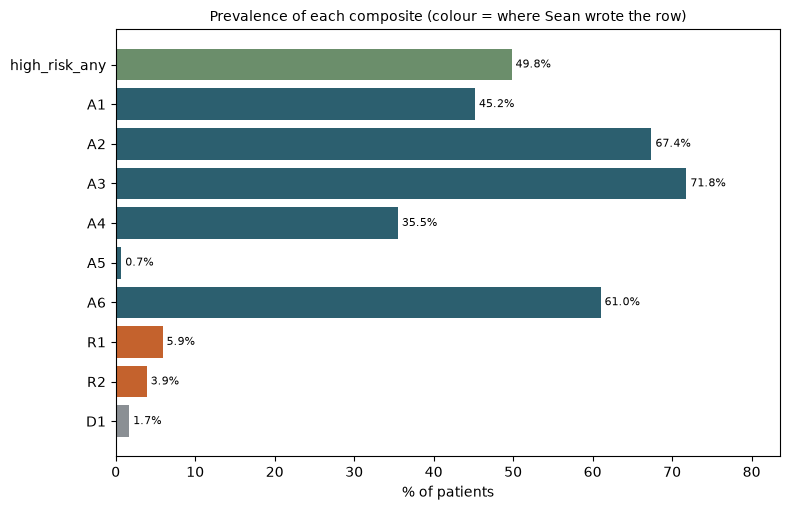

,patients,% of patients
approve,134460,89.2
approve + refer,7366,4.9
none of the rows,3171,2.1
refer,3106,2.1
refer + decline,1349,0.9
decline,1187,0.8
approve + decline,14,0.0
approve + refer + decline,11,0.0


In [6]:
mo      = pt['months_out']
hr_any  = P[HIGH_RISK].any(axis=1)
hr_n    = P[HIGH_RISK].sum(axis=1)
Q = pd.DataFrame(index=pt.index)
Q['high_risk_any']  = hr_any
Q['A1'] = ~hr_any & (mo > CUT['recent'])
Q['A2'] = P['ekg_no_abnormal_code'] & ~P['hx_cad']
Q['A3'] = P['no_further_cardiac_testing'] & ~P['hx_cad'] & (mo > CUT['recent'])
Q['A4'] = P['explained_dx'] & ~P['hx_cad']
Q['A5'] = P['noncardiac_cp']
Q['A6'] = mo > CUT['old']
Q['R1'] = hr_any & (mo < CUT['recent'])
Q['R2'] = P['no_firm_dx'] & (mo < CUT['recent'])
Q['D1'] = P['hx_cad'] & (mo < CUT['cad'])
COMP = pd.DataFrame([
    ('high_risk_any', 'summary',  'any high-risk feature', 'age_sex_high_risk OR hx_cad OR abnormal_ekg OR extra_cardiac_testing OR rx_nitrates'),
    ('A1', 'approve', 'No high risk features and > 6 months out',                 'NOT high_risk_any AND months out > 6'),
    ('A2', 'approve', 'Any time and EKG normal, no Hx of CAD',                    'ekg_no_abnormal_code AND NOT hx_cad'),
    ('A3', 'approve', 'No further cardiac testing, no Hx of CAD, > 6 months out',  'no_further_cardiac_testing AND NOT hx_cad AND months out > 6'),
    ('A4', 'approve', 'No Hx of CAD and later coded as anxiety, GI, strain, costochondritis', 'explained_dx AND NOT hx_cad'),
    ('A5', 'approve', 'Later noted as intercostal or non-cardiac chest pain',     'noncardiac_cp'),
    ('A6', 'approve', 'Coded > 2 years ago',                                      'months out > 24'),
    ('R1', 'refer',   'Any high risk features and < 6 months',                    'high_risk_any AND months out < 6'),
    ('R2', 'refer',   'No firm diagnosis and < 6 months',                         'no_firm_dx AND months out < 6'),
    ('D1', 'decline', 'Hx of CAD and < 1 year',                                   'hx_cad AND months out < 12')],
    columns=['id', 'Sean column', "Sean's words", 'formula']).set_index('id')
COMP.insert(3, 'n', Q.sum().astype(int)[COMP.index].to_numpy())
COMP.insert(4, '% of patients', (COMP['n'] / N * 100).round(1).to_numpy())
display(COMP)
print("Not computable (no result values in claims): approve row 'All cardiac testing wnl'. Table rating: not in claims.")

print("\nnumber of high-risk features per patient (of 5):")
display(hr_n.value_counts().sort_index().rename('patients').to_frame().assign(**{'%': lambda d: (d['patients'] / N * 100).round(1)}))

_col = {'approve': '#2C5F6F', 'refer': '#C4622D', 'decline': '#8A8F94', 'summary': '#6B8E6B'}
_c = COMP.iloc[::-1]
fig, ax = plt.subplots(figsize=(8, 0.4 * len(_c) + 1.2))
ax.barh(_c.index, _c['% of patients'], color=[_col[s] for s in _c['Sean column']])
for y, v in enumerate(_c['% of patients']):
    ax.text(v + 0.5, y, f'{v:.1f}%', va='center', fontsize=8)
ax.set_xlim(0, _c['% of patients'].max() * 1.15 + 1); ax.set_xlabel('% of patients')
ax.set_title('Prevalence of each composite (colour = where Sean wrote the row)', fontsize=10)
plt.tight_layout(); plt.show()

# who meets rows of which columns (counts only, no decision)
colmat = pd.DataFrame({'approve column': Q[['A1', 'A2', 'A3', 'A4', 'A5', 'A6']].any(axis=1),
                       'refer column':   Q[['R1', 'R2']].any(axis=1),
                       'decline column': Q[['D1']].any(axis=1)})
ovl = colmat.value_counts().rename('patients').to_frame()
ovl['% of patients'] = (ovl['patients'] / N * 100).round(1)
ovl.index = [' + '.join(c.replace(' column', '') for c, v in zip(colmat.columns, idx) if v) or 'none of the rows' for idx in ovl.index]
print("patients by the columns whose rows they meet (a patient can meet rows of several columns):")
display(ovl)

## A6 · OMOP entities behind the rules

Two tables. **Predicates**: every predicate of A4 in the same order (high risk, low risk, later coded, derived), with Sean's words, the time form and the OMOP concepts it reads (`concept_name · concept_id`, most patients first); a derived predicate names the predicates it combines. **Composites**: each composite of A5 with the predicates it combines and the code sets it reaches. `C` and `F`, the latest and first chest pain code, come from the anchor `chest_pain` (last row of the first table); `R` is the application date, not an OMOP concept. Both tables are in the export, with a long sheet of every concept.


In [7]:
# A6 · The OMOP entities behind each predicate and composite
import html, re
from IPython.display import HTML

# predicate -> (Sean's words, time form, code sets it reads, predicates it is built from); 'person' = the Person table
RULES = {
    'age_sex_high_risk':          ("Male > 45, Female > 55",                                        'at C',                 ['person'],                              []),
    'hx_cad':                     ("Previous Dx of CAD",                                            'at or before C',       ['uw_cad_dx'],                           []),
    'abnormal_ekg':               ("Abnormal EKG",                                                  'up to R',              ['uw_abnormal_ekg'],                     []),
    'extra_cardiac_testing':      ("Additional cardiac testing",                                    'after C',              ['uw_cardiac_testing'],                  []),
    'rx_nitrates':                ("Rx nitrates",                                                   'up to R',              ['nitrates'],                            []),
    'troponin':                   ("Troponin testing",                                              'up to R',              ['troponin'],                            []),
    'ekg':                        ("EKG",                                                           'up to R',              ['ekg'],                                 []),
    'gerd':                       ("GERD",                                                          'up to R',              ['gerd'],                                []),
    'anxiety':                    ("Anxiety",                                                       'up to R',              ['anxiety'],                             []),
    'gi_dx':                      ("GERD, other GI related Dx, later coded",                        'after C',              ['gerd', 'uw_gi_dx'],                    []),
    'anxiety_later':              ("Anxiety, later coded",                                          'after C',              ['anxiety'],                             []),
    'muscle_strain':              ("Muscle strain, later coded",                                    'after C',              ['uw_muscle_strain'],                    []),
    'costochondritis':            ("Costochondritis, later coded",                                  'after C',              ['costochondritis'],                     []),
    'noncardiac_cp':              ("Later noted as intercostal or non-cardiac chest pain",          'after the first chest pain code F', ['uw_noncardiac_cp'],         []),
    'explained_dx':               ("Later coded as anxiety, GI, muscle strain or costochondritis",  'after C',              [],  ['anxiety_later', 'gi_dx', 'muscle_strain', 'costochondritis']),
    'ekg_no_abnormal_code':       ("EKG normal (claims proxy: an EKG and no abnormal-EKG code)",    'up to R',              [],  ['ekg', 'abnormal_ekg']),
    'no_further_cardiac_testing': ("No further cardiac testing",                                    'after C',              [],  ['extra_cardiac_testing']),
    'no_firm_dx':                 ("No firm diagnosis (none of the diagnoses of the draft)",       'up to R',              ['uw_cad_dx', 'gerd', 'uw_gi_dx', 'anxiety', 'uw_muscle_strain', 'costochondritis', 'uw_noncardiac_cp'], []),
}
assert set(RULES) == set(P.columns), f"RULES and the predicates of A4 differ: {sorted(set(RULES) ^ set(P.columns))}"
assert ({s for _, _, sets, _ in RULES.values() for s in sets} - {'person'}) | {'chest_pain'} == set(NEEDED), "the code sets of RULES and NEEDED differ"

cinfo = concept.drop_duplicates('concept_id').set_index('concept_id')
npat  = ev.groupby('concept_id')['person_id'].nunique()                       # patients per concept, events up to R
_pg   = eo._read(OUT_DIR, 'person', columns=['gender_concept_id', 'gender_source_value']).dropna().drop_duplicates().sort_values('gender_source_value')
PERSON_LINES = [f"person.gender_source_value: {g} · gender_concept_id {int(c)}" for g, c in zip(_pg['gender_source_value'], _pg['gender_concept_id'])] + ['person.birth_datetime']

def concepts_of(tag):
    d = cinfo.loc[sorted(codesets[tag]), ['concept_name', 'domain_id', 'vocabulary_id', 'concept_class_id']].copy()
    d['patients'] = npat.reindex(d.index).fillna(0).astype(int)
    return d.reset_index().sort_values(['patients', 'concept_name'], ascending=[False, True])

def entity_blocks(tags):                       # [(header, [lines])] per code set, shared by the screen table and the workbook
    out = []
    for t in tags:
        if t == 'person':
            out.append(('Person table', PERSON_LINES))
            continue
        d = concepts_of(t)
        out.append((f"{', '.join(sorted(d['domain_id'].astype(str).unique()))} · {', '.join(sorted(d['vocabulary_id'].astype(str).unique()))} ({t}, {len(d)} concepts)",
                    [f"{n} · {i}" for n, i in zip(d['concept_name'], d['concept_id'])]))
    return out
as_text = lambda blocks: '\n'.join(h + '\n' + '\n'.join('  ' + l for l in ls) for h, ls in blocks)
as_html = lambda blocks: ''.join(f"<div style='margin-bottom:6px'><b>{html.escape(h)}</b>" + ''.join(f"<div>{html.escape(l)}</div>" for l in ls) + '</div>' for h, ls in blocks)

def html_table(head, rows):
    th = ''.join(f"<th style='text-align:left;padding:4px 8px;border-bottom:2px solid #8886'>{h}</th>" for h in head)
    tr = ''.join('<tr>' + ''.join(f"<td style='vertical-align:top;padding:4px 8px;border-bottom:1px solid #8884'>{c}</td>" for c in r) + '</tr>' for r in rows)
    return f"<table style='border-collapse:collapse;font-size:12px'><tr>{th}</tr>{tr}</table>"

def reaches(pred):                             # code sets a predicate reads, directly or through the predicates it combines
    _, _, sets, parts = RULES[pred]
    return list(dict.fromkeys(sets + [s for q in parts for s in reaches(q)]))

# ---- table 1: predicates (high risk, low risk, later coded, derived), then the anchor
rows1 = [dict(group=GROUP[p], predicate=p, words=RULES[p][0], when=RULES[p][1], built=RULES[p][3], sets=RULES[p][2]) for p in P.columns]
rows1.append(dict(group='anchor', predicate='chest_pain', words='Patient with chest pain', when='latest up to R = C, first = F', built=[], sets=['chest_pain']))
ent_pred_tbl = pd.DataFrame([{'group': r['group'], 'predicate': r['predicate'], "Sean's words": r['words'], 'time form': r['when'],
                              'built from': ', '.join(r['built']), 'OMOP entities (name · concept_id)': as_text(entity_blocks(r['sets']))} for r in rows1])
display(HTML('<h4>Predicates</h4>' + html_table(['group', 'predicate', "Sean's words", 'time form', 'OMOP entities (name · concept_id)'],
    [[r['group'], f"<code>{r['predicate']}</code>", html.escape(r['words']), html.escape(r['when']),
      ('<div><i>built from:</i> ' + ', '.join(f'<code>{b}</code>' for b in r['built']) + '</div>' if r['built'] else '') + as_html(entity_blocks(r['sets']))] for r in rows1])))

# ---- table 2: composites
rows2 = []
for cid, r in COMP.iterrows():
    used = [p for p in RULES if re.search(rf'\b{p}\b', r['formula'])]
    uses_mo = 'months out' in r['formula']
    sets = list(dict.fromkeys([s for p in used for s in reaches(p)] + (['chest_pain'] if uses_mo else [])))
    rows2.append({'id': cid, 'Sean column': r['Sean column'], "Sean's words": r["Sean's words"],
                  'built from': ', '.join(used + (['months out (R - C)'] if uses_mo else [])),
                  'code sets reached': ', '.join('person (sex, birth date)' if s == 'person' else f"{s} ({len(codesets[s])} concepts)" for s in sets)})
ent_comp_tbl = pd.DataFrame(rows2)
display(HTML('<h4>Composites</h4>' + html_table(list(ent_comp_tbl.columns), [[html.escape(str(v)) for v in r] for r in ent_comp_tbl.itertuples(index=False)])
             + "<p style='font-size:12px'>Concepts are the standard concepts of each code set that the extract holds, most patients first (patients counted up to R). "
               "<code>C</code> and <code>F</code> come from <code>chest_pain</code>; <code>R</code> is the application date.</p>"))

# ---- long sheet for the workbook: every concept of every code set, with the predicates that read it
ent_long = pd.concat([concepts_of(t).assign(**{'code set': t, 'predicates': ', '.join(p for p in RULES if t in RULES[p][2])}) for t in NEEDED], ignore_index=True)
ent_long = ent_long[['code set', 'predicates', 'concept_id', 'concept_name', 'domain_id', 'vocabulary_id', 'concept_class_id', 'patients']]


id,Sean column,Sean's words,built from,code sets reached
high_risk_any,summary,any high-risk feature,"age_sex_high_risk, hx_cad, abnormal_ekg, extra_cardiac_testing, rx_nitrates","person (sex, birth date), uw_cad_dx (22 concepts), uw_abnormal_ekg (1 concepts), uw_cardiac_testing (55 concepts), nitrates (22 concepts)"
A1,approve,No high risk features and > 6 months out,months out (R - C),chest_pain (4 concepts)
A2,approve,"Any time and EKG normal, no Hx of CAD","hx_cad, ekg_no_abnormal_code","uw_cad_dx (22 concepts), ekg (5 concepts), uw_abnormal_ekg (1 concepts)"
A3,approve,"No further cardiac testing, no Hx of CAD, > 6 months out","hx_cad, no_further_cardiac_testing, months out (R - C)","uw_cad_dx (22 concepts), uw_cardiac_testing (55 concepts), chest_pain (4 concepts)"
A4,approve,"No Hx of CAD and later coded as anxiety, GI, strain, costochondritis","hx_cad, explained_dx","uw_cad_dx (22 concepts), anxiety (12 concepts), gerd (4 concepts), uw_gi_dx (69 concepts), uw_muscle_strain (4 concepts), costochondritis (1 concepts)"
A5,approve,Later noted as intercostal or non-cardiac chest pain,noncardiac_cp,uw_noncardiac_cp (1 concepts)
A6,approve,Coded > 2 years ago,months out (R - C),chest_pain (4 concepts)
R1,refer,Any high risk features and < 6 months,months out (R - C),chest_pain (4 concepts)
R2,refer,No firm diagnosis and < 6 months,"no_firm_dx, months out (R - C)","uw_cad_dx (22 concepts), gerd (4 concepts), uw_gi_dx (69 concepts), anxiety (12 concepts), uw_muscle_strain (4 concepts), costochondritis (1 concepts), uw_noncardiac_cp (1 concepts), chest_pain (4 concepts)"
D1,decline,Hx of CAD and < 1 year,"hx_cad, months out (R - C)","uw_cad_dx (22 concepts), chest_pain (4 concepts)"


## A7 · Sensitivity to the time cut-offs

The time rows (A1, A3, A6, R1, R2, D1) depend on months out = `R - C`, with `R` the application date. The table repeats them at other cut-offs.


application date R: 2021-02-02 to 2026-11-04


,no high risk and > cut (A1),high risk and < cut (R1),no firm dx and < cut (R2),Hx CAD and < cut (D1),coded > cut (A6)
cut (months),,,,,
3,"72,080","4,310","2,858",669,"142,850"
6,"68,157","8,884","5,859","1,360","134,353"
12,"61,102","17,275","11,426","2,561","118,907"
24,"48,510","31,638","21,396","4,377","91,952"


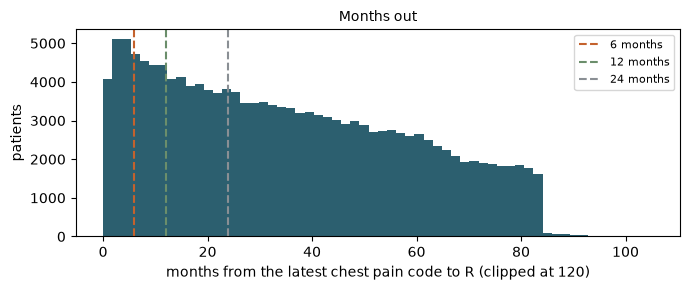

In [8]:
rows = []
for t in (3, 6, 12, 24):
    rows.append({'cut (months)': t,
                 'no high risk and > cut (A1)': int((~hr_any & (mo > t)).sum()),
                 'high risk and < cut (R1)':    int((hr_any & (mo < t)).sum()),
                 'no firm dx and < cut (R2)':   int((P['no_firm_dx'] & (mo < t)).sum()),
                 'Hx CAD and < cut (D1)':       int((P['hx_cad'] & (mo < t)).sum()),
                 'coded > cut (A6)':            int((mo > t).sum())})
sens = pd.DataFrame(rows).set_index('cut (months)')
display(sens.style.format('{:,}'))
print(f"application date R: {pt['ref_date'].min().date()} to {pt['ref_date'].max().date()}")

plt.figure(figsize=(7, 3))
plt.hist(mo.dropna().clip(upper=120), bins=60, color='#2C5F6F')
for t, c in ((CUT['recent'], '#C4622D'), (CUT['cad'], '#6B8E6B'), (CUT['old'], '#8A8F94')):
    plt.axvline(t, ls='--', c=c, label=f'{t} months')
plt.xlabel('months from the latest chest pain code to R (clipped at 120)'); plt.ylabel('patients'); plt.legend(fontsize=8)
plt.title('Months out', fontsize=10); plt.tight_layout(); plt.show()

## A8 · Limits and open questions

- **Reference date.** `R` is the application date: the latest interview start over the person's policies, taken in `sql/chest_pain_cohort.sql` v0.3 (`policy.csv`). Events after `R` are ignored; a person with no date is left out; a later re-application moves `R` and `C` with it.
- **Age and sex** are read at `C`, the latest chest pain code, not at `R`.
- **Age limits are strict** (Zack, 2026-11-04): `>`, not `>=`. A man older than 45 and a woman older than 55 at `C`, in completed years (46 and 56 and up). Before, the 45th and 55th birthday counted.
- **"< 1 year" (decline)** (confirmed by Zack, 2026-11-04): any history of CAD, and the last chest pain code within the 12 months before the application date. The clock runs from `C` to `R`, not from the CAD diagnosis. `hx_cad` reads CAD at or before `C`.
- **"Later coded".** Strictly after `C`. `noncardiac_cp` is read after the first chest pain code `F`, because those codes are chest pain codes.
- **`hx_cad`.** CAD, old infarct and angina diagnoses at or before `C`; "history of ..." status concepts and prior CABG / stent are out.
- **`no_firm_dx`** (Zack, 2026-11-04): none of the diagnoses of the draft appears up to `R`: CAD, GERD, other GI, anxiety, muscle strain, costochondritis, intercostal / non-cardiac chest pain, at any time. The coded abnormal EKG finding is a feature of the draft, not a diagnosis, so it does not count.
- **`ekg_no_abnormal_code`.** An EKG and no coded abnormal finding; not "EKG normal" (claims have no results).
- **Precedence.** None applied. **Excluded.** Patients with no chest pain code on or before `R` (counted in A3).


## A9 · Export

The tables in one workbook, with the OMOP entities of A6.


In [9]:
os.makedirs('outputs', exist_ok=True)
XLSX = 'outputs/sean_predicates_composites_prevalence.xlsx'
with pd.ExcelWriter(XLSX) as xw:
    pred_tbl.to_excel(xw, sheet_name='predicates')
    COMP.to_excel(xw, sheet_name='composites')
    ovl.to_excel(xw, sheet_name='columns overlap')
    sens.to_excel(xw, sheet_name='time cut-offs')
    NOT_COMPUTABLE.to_excel(xw, sheet_name='not computable', index=False)
    cs_tbl.to_excel(xw, sheet_name='code sets')
    ent_pred_tbl.to_excel(xw, sheet_name='predicate entities', index=False)
    ent_comp_tbl.to_excel(xw, sheet_name='composite entities', index=False)
    ent_long.to_excel(xw, sheet_name='entity concepts', index=False)
print(f"saved {XLSX}  ({N:,} patients; application date {pt['ref_date'].min().date()} to {pt['ref_date'].max().date()}; code sets {CODESETS_FILE})")

saved outputs/sean_predicates_composites_prevalence.xlsx  (150,664 patients; application date 2021-02-02 to 2026-11-04; code sets codesets_sean_v2.yaml)
